# 04 – Phân cụm bằng các phương pháp hiện đại: DBSCAN, HDBSCAN, UMAP + clustering, Autoencoder + K-Means

**Mục tiêu:** đề bài yêu cầu so sánh với các phương pháp hiện đại. Notebook này kiểm tra hai hướng chính để khắc phục điểm yếu của các thuật toán cổ điển (phải chọn K trước, giả định cụm hình cầu/elip, nhạy với ngoại lệ):
1. **Phân cụm dựa trên mật độ**: DBSCAN (1996) làm mốc, và **HDBSCAN** (Campello et al., 2013; McInnes et al., 2017). HDBSCAN tự xác định số cụm, phát hiện nhiễu và cho điểm bất thường (GLOSH).
2. **Học biểu diễn (representation learning) rồi phân cụm**: **UMAP** (McInnes et al., 2018) + HDBSCAN/K-Means, và **Autoencoder + K-Means** (dạng hai giai đoạn của deep clustering, như bước khởi tạo của DEC – Xie et al., 2016).

**Nguyên tắc so sánh công bằng:** mọi chỉ số nội bộ (Silhouette, Davies-Bouldin, Calinski-Harabasz) đều được tính trong **cùng không gian RFM 3 chiều đã chuẩn hóa**, giống notebook 03, và **bỏ qua các điểm nhiễu** (nhãn −1). Tỉ lệ nhiễu được báo cáo riêng.

## 1. Tóm tắt nguyên lý

| Phương pháp | Ý tưởng chính | Tham số chính | Ưu điểm | Hạn chế |
|---|---|---|---|---|
| **DBSCAN** | Điểm lõi là điểm có ≥ `min_samples` điểm trong bán kính `eps`. Các điểm lõi nối với nhau tạo thành cụm; điểm không thuộc cụm nào là nhiễu | `eps`, `min_samples` | Cụm hình dạng bất kỳ; không cần chọn K; phát hiện nhiễu | Một `eps` duy nhất cho mọi vùng, nên thất bại khi mật độ các vùng khác nhau |
| **HDBSCAN** | (1) Tính **khoảng cách khả đạt tương hỗ** $d_{mreach}(a,b)=\max\{core_k(a), core_k(b), d(a,b)\}$; (2) dựng cây khung nhỏ nhất (MST); (3) tạo cây phân cấp và **nén** (condensed tree) với `min_cluster_size`; (4) chọn các cụm có **độ ổn định** $\sum_{p}(\lambda_p-\lambda_{birth})$ lớn nhất (với $\lambda = 1/d$) | `min_cluster_size`, `min_samples` | Tương đương DBSCAN với mọi giá trị `eps` cùng lúc; xử lý được mật độ thay đổi; cho xác suất thành viên và điểm bất thường **GLOSH** | Có thể gán rất nhiều điểm là nhiễu khi dữ liệu không có vùng mật độ tách biệt |
| **UMAP** | Xây đồ thị k láng giềng có trọng số mờ (fuzzy simplicial set) trong không gian gốc, rồi tìm cách nhúng xuống ít chiều sao cho đồ thị tương ứng giống nhất (cực tiểu cross-entropy) | `n_neighbors`, `min_dist` | Giữ được cấu trúc cục bộ và một phần cấu trúc toàn cục; nhanh hơn t-SNE; giúp HDBSCAN hoạt động tốt hơn | Khoảng cách và mật độ trong không gian nhúng **không còn ý nghĩa trực tiếp**; kết quả phụ thuộc tham số và random seed |
| **Autoencoder + K-Means** | Mạng nơ-ron gồm encoder $f: \mathbb R^d\to\mathbb R^m$ và decoder $g$, huấn luyện cực tiểu lỗi tái tạo $\lVert x - g(f(x))\rVert^2$; sau đó phân cụm trên biểu diễn ẩn $z=f(x)$ | Kiến trúc mạng, số chiều ẩn $m$, K | Học được quan hệ phi tuyến giữa nhiều đặc trưng | Biểu diễn được tối ưu cho việc tái tạo, không phải cho phân cụm; khó diễn giải; cần dữ liệu lớn |

**DBCV** (Density-Based Clustering Validation, Moulavi et al., 2014) là chỉ số đánh giá dành cho phân cụm dựa trên mật độ, nhận giá trị trong khoảng [−1, 1]. Thư viện `hdbscan` cung cấp phiên bản xấp xỉ qua thuộc tính `relative_validity_`.

## 2. Đọc dữ liệu

In [1]:
import sys, warnings, time
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hdbscan
import umap
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

from src.cluster_utils import (internal_metrics, timed_fit, relabel_by_value, bootstrap_stability,
                               agreement, profile, name_clusters)
from src.modern import UMAPCluster, AutoencoderKMeans, dequantize
from src import viz
viz.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
OUT = Path("../outputs"); SEED = 42

X = pd.read_csv(OUT / "rfm_model_input.csv", index_col=0); Xv = X.values
Xe = pd.read_csv(OUT / "rfm_ext_input.csv", index_col=0).values
rfm = pd.read_csv(OUT / "rfm_features.csv", index_col=0)
rule = pd.read_csv(OUT / "rfm_scores.csv", index_col=0)["Segment_Rule"]
classic = pd.read_csv(OUT / "labels_classic.csv", index_col=0)
km_lab = classic["KMeans"].values
print("RFM 3D:", Xv.shape, "| RFM mở rộng 6D:", Xe.shape)

def summarize(name, lab, t=np.nan, X_eval=Xv):
    lab = np.asarray(lab); m = lab != -1
    return {"Phương pháp": name, "Số cụm": len(set(lab[m])), "% nhiễu": 100 * (~m).mean(),
            **internal_metrics(X_eval, lab), "ARI với K-Means": agreement(km_lab[m], lab[m])["ARI"] if m.any() else np.nan,
            "Thời gian (s)": t}

RFM 3D: (4320, 3) | RFM mở rộng 6D: (4320, 6)


## 3. DBSCAN – mốc so sánh cho nhóm thuật toán dựa trên mật độ
### 3.1 Chọn `eps` bằng đồ thị k-distance

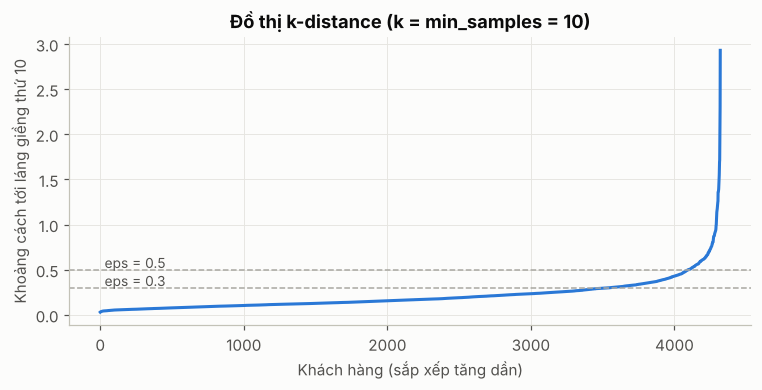

Phân vị 50/90/95/99% của k-distance: [0.166 0.376 0.504 0.872]


In [2]:
MS = 10
dist, _ = NearestNeighbors(n_neighbors=MS).fit(Xv).kneighbors(Xv)
kd = np.sort(dist[:, -1])
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(np.arange(len(kd)), kd, color=viz.MAIN)
for e in [0.3, 0.5]:
    ax.axhline(e, color=viz.GREY, linestyle="--", linewidth=1)
    ax.text(30, e + .02, f"eps = {e}", color=viz.INK2, fontsize=9)
ax.set_xlabel("Khách hàng (sắp xếp tăng dần)"); ax.set_ylabel(f"Khoảng cách tới láng giềng thứ {MS}")
ax.set_title(f"Đồ thị k-distance (k = min_samples = {MS})")
viz.save(fig, "fig26_dbscan_kdistance"); plt.show()
print("Phân vị 50/90/95/99% của k-distance:", np.round(np.percentile(kd, [50, 90, 95, 99]), 3))

In [3]:
rows = []
for eps in [0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6]:
    _, lab, t = timed_fit(lambda: DBSCAN(eps=eps, min_samples=MS), Xv)
    sizes = np.sort(np.bincount(lab[lab != -1]))[::-1] if (lab != -1).any() else []
    rows.append({"eps": eps, **summarize(f"DBSCAN eps={eps}", lab, t), "Kích thước 4 cụm lớn nhất": list(sizes[:4])})
db_scan = pd.DataFrame(rows).set_index("eps").drop(columns="Phương pháp")
db_scan

,Số cụm,% nhiễu,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI với K-Means,Thời gian (s),Kích thước 4 cụm lớn nhất
eps,,,,,,,,
0.200,13,29.954,0.092,1.470,377.065,0.379,0.020,"[1375, 696, 370, 260]"
0.250,9,17.315,0.102,1.619,795.944,0.375,0.020,"[1407, 764, 589, 423]"
0.300,4,10.486,0.146,2.211,"1,808.655",0.365,0.025,"[1422, 1210, 791, 444]"
0.350,4,6.528,0.159,1.361,"1,427.729",0.345,0.026,"[1778, 1447, 807, 6]"
0.400,3,4.514,0.179,1.671,"2,089.889",0.338,0.030,"[1847, 1462, 816]"
0.500,2,2.477,0.298,1.056,"2,419.861",0.204,0.048,"[2733, 1480]"
0.600,1,1.227,NaN,NaN,NaN,0.000,0.060,[4267]


**Nhận xét – DBSCAN:**
- Đồ thị k-distance **không có "khuỷu" rõ ràng** ở phần lớn dữ liệu: khoảng cách tăng từ từ (trung vị 0,17; phân vị 90% là 0,38) rồi chỉ bật lên ở khoảng 1–2% điểm cuối (phân vị 99% là 0,87). Không có một ngưỡng `eps` tự nhiên nào tách các vùng mật độ.
- Kết quả **rất nhạy với `eps`**: chỉ thay đổi eps từ 0,2 đến 0,6, số cụm giảm từ 13 xuống 1 và tỉ lệ nhiễu từ 30% xuống 1%. Với eps = 0,3 (4 cụm, 10,5% nhiễu), Silhouette chỉ đạt 0,146 và Davies-Bouldin là 2,21, đều kém xa K-Means.
- Khi đối chiếu cụm DBSCAN (eps = 0,3) với Frequency: cụm 1 là 1.422 khách có F = 1, cụm 3 là 791 khách có F = 2, cụm 2 là 444 khách có F = 3, còn cụm 0 gồm phần lớn khách có F ≥ 4. Như vậy **DBSCAN đang chia khách theo số đơn hàng**, chứ không theo hành vi RFM tổng hợp. Hiện tượng này được phân tích kỹ ở mục 4.

## 4. HDBSCAN trên không gian RFM
### 4.1 Khảo sát tham số

In [4]:
rows = []
for mcs in [20, 50, 100, 200, 400]:
    for ms in [None, 10]:
        mk = lambda: hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=ms, gen_min_span_tree=True)
        model, lab, t = timed_fit(mk, Xv)
        rows.append({"min_cluster_size": mcs, "min_samples": ms if ms else "= mcs",
                     **summarize("", lab, t), "DBCV": model.relative_validity_ if len(set(lab)) > 1 else np.nan})
hdb_scan = pd.DataFrame(rows).drop(columns="Phương pháp").set_index(["min_cluster_size", "min_samples"])
hdb_scan

Số cụm  % nhiễu  Silhouette  Davies-Bouldin  \
min_cluster_size min_samples                                                
20               = mcs             3   14.514       0.196           1.613   
                 10                6   20.833       0.112           2.047   
50               = mcs             2   13.912       0.329           1.018   
                 10                5   21.528       0.127           2.304   
100              = mcs             2   27.778       0.363           0.988   
                 10                5   21.528       0.127           2.304   
200              = mcs             2   53.009       0.455           0.844   
                 10                4   13.634       0.140           2.180   
400              = mcs             0  100.000         NaN             NaN   
                 10                3    7.685       0.182           1.662   

                              Calinski-Harabasz  ARI với K-Means  \
min_cluster_size min_samples                                       
20               = mcs                2,122.410            0.373   
                 10                     915.554            0.356   
50               = mcs                2,542.045            0.237   
                 10                   1,065.474            0.353   
100              = mcs                2,503.437            0.297   
                 10                   1,065.474            0.353   
200              = mcs                2,491.530            0.501   
                 10                   1,656.719            0.363   
400              = mcs                      NaN              NaN   
                 10                   2,105.951            0.346   

                              Thời gian (s)  DBCV  
min_cluster_size min_samples                       
20               = mcs                0.062 0.005  
                 10                   0.060 0.018  
50               = mcs                0.086 0.000  
                 10                   0.065 0.011  
100              = mcs                0.118 0.001  
                 10                   0.058 0.011  
200              = mcs                0.140 0.000  
                 10                   0.051 0.011  
400              = mcs                0.223   NaN  
                 10                   0.052 0.011

**Nhận xét – khảo sát tham số HDBSCAN:**
- Kết quả **thay đổi mạnh theo tham số**: từ 2 đến 6 cụm, tỉ lệ nhiễu từ 7,7% đến 100%. Với `min_samples` mặc định (= `min_cluster_size`), cứ tăng `min_cluster_size` thì tỉ lệ nhiễu lại tăng mạnh (14% lên 28% rồi 53%), và đến 400 thì **toàn bộ dữ liệu là nhiễu**.
- Một số cấu hình có Silhouette "đẹp" (0,455 với mcs = 200), nhưng đó là vì **53% khách khó phân loại đã bị gạt ra làm nhiễu**, và Silhouette chỉ được tính trên phần còn lại. Đây là cái bẫy khi so sánh thuật toán có nhiễu với thuật toán không có nhiễu.
- **DBCV ≈ 0,00–0,02 với mọi cấu hình**. Theo thang [−1; 1] của chỉ số này, giá trị gần 0 nghĩa là **không có cấu trúc cụm dựa trên mật độ đáng kể**: các "cụm" không tách biệt với nhau bởi vùng thưa.
- Nhóm chọn cấu hình đại diện **min_cluster_size = 50, min_samples = 10** (5 cụm, 21,5% nhiễu) để phân tích tiếp, vì đây là cấu hình ít nhạy với tham số nhất (mcs = 50 và mcs = 100 cho cùng một kết quả).

### 4.2 HDBSCAN đã "phát hiện" điều gì? Đối chiếu cụm với Frequency

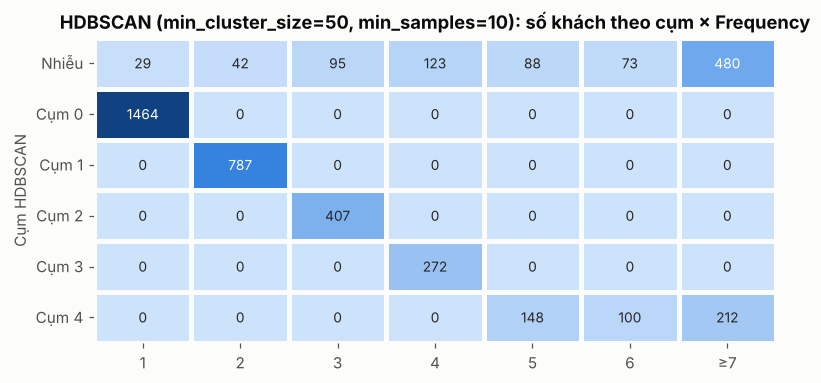

In [5]:
hdb = hdbscan.HDBSCAN(min_cluster_size=50, min_samples=10, gen_min_span_tree=True)
t0 = time.perf_counter(); hdb_lab = hdb.fit_predict(Xv); hdb_time = time.perf_counter() - t0
ct = pd.crosstab(pd.Series(hdb_lab, index=X.index, name="Cụm HDBSCAN"), rfm["Frequency"].clip(upper=7).rename("Frequency (≥7 gộp)"))
ct.columns = [str(c) if c < 7 else "≥7" for c in ct.columns]
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(ct, annot=True, fmt="d", cmap=viz.SEQ_CMAP, cbar=False, ax=ax, linewidths=2, linecolor="#fcfcfb", annot_kws={"size": 9})
ax.set_title("HDBSCAN (min_cluster_size=50, min_samples=10): số khách theo cụm × Frequency")
ax.set_yticklabels(["Nhiễu" if t.get_text() == "-1" else f"Cụm {t.get_text()}" for t in ax.get_yticklabels()], rotation=0)
viz.save(fig, "fig27_hdbscan_vs_frequency"); plt.show()

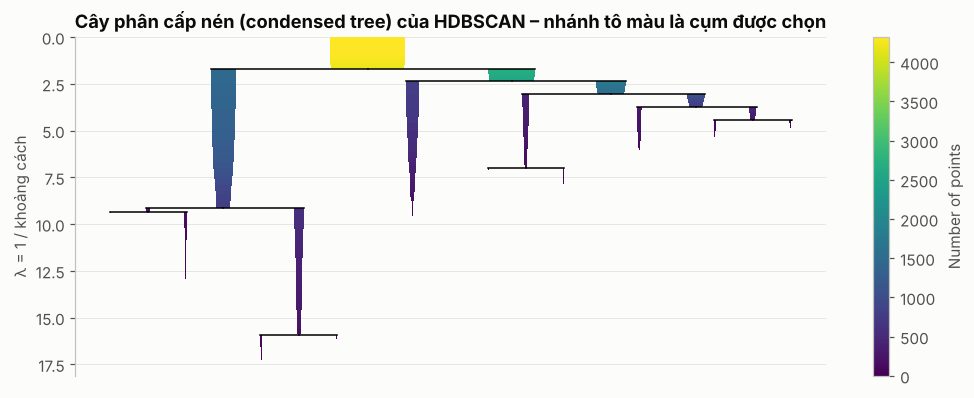

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
hdb.condensed_tree_.plot(select_clusters=True, selection_palette=viz.PALETTE, axis=ax, colorbar=True)
from matplotlib.patches import Ellipse
for p in list(ax.patches):            # bỏ các ellipse đánh dấu (không tương thích matplotlib mới); màu nhánh vẫn giữ
    if isinstance(p, Ellipse): p.remove()
ax.set_title("Cây phân cấp nén (condensed tree) của HDBSCAN – nhánh tô màu là cụm được chọn")
ax.set_ylabel("λ = 1 / khoảng cách")
viz.save(fig, "fig28_hdbscan_condensed_tree"); plt.show()

**Nhận xét – phát hiện quan trọng: các cụm HDBSCAN là "mức Frequency"**
- Đối chiếu cho thấy **mỗi cụm HDBSCAN ứng đúng với một giá trị Frequency**: cụm 0 gồm 1.464 khách đều có F = 1, cụm 1 gồm 787 khách đều có F = 2, cụm 2 gồm 407 khách đều có F = 3, cụm 3 gồm 272 khách đều có F = 4, và cụm 4 là các khách có F ≥ 5. Không có cụm nào trộn hai mức Frequency.
- **Giải thích:** Frequency là biến đếm nên rất nhiều khách có **cùng một giá trị**. Sau log1p và chuẩn hóa, mỗi mức Frequency trở thành một "lát cắt mỏng" (mặt phẳng) có mật độ điểm rất cao trong không gian 3 chiều, và giữa các lát là khoảng trống. Với thuật toán dựa trên mật độ, đây chính là định nghĩa của "cụm". Hiện tượng này **cùng bản chất** với sự suy biến của GMM ở notebook 03.
- Cây phân cấp nén (condensed tree) minh họa quá trình này: các nhánh tách ra lần lượt từ gốc là các nhóm F = 1, 2, 3, 4…, và mỗi nhánh tồn tại lâu (λ lớn) vì mật độ bên trong rất cao.
- Về kinh doanh, cách chia này **không mang lại thông tin mới** (chỉ cần đếm số đơn hàng là có), và bỏ qua hoàn toàn Recency và Monetary.

### 4.3 Kiểm chứng: loại bỏ tính rời rạc (dequantization) thì còn cụm mật độ không?
Giả thuyết: các "cụm" mà HDBSCAN tìm thấy là **giả tạo**, sinh ra do Frequency là biến đếm (nhiều khách trùng giá trị). Để kiểm chứng, nhóm cộng nhiễu đều $U(-0{,}5;\,0{,}5)$ vào Frequency và $U(0;1)$ ngày vào Recency, sau đó log1p và chuẩn hóa như cũ, rồi chạy lại HDBSCAN. Phép biến đổi này không làm thay đổi thứ tự hay ý nghĩa của dữ liệu, chỉ "làm mịn" các giá trị trùng nhau.

In [7]:
Xd = StandardScaler().fit_transform(np.log1p(dequantize(rfm, seed=SEED)))
rows = []
for mcs in [20, 50, 100, 200]:
    for ms in [None, 10]:
        model, lab, t = timed_fit(lambda: hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=ms), Xd)
        rows.append({"min_cluster_size": mcs, "min_samples": ms if ms else "= mcs", **summarize("", lab, t)})
deq = pd.DataFrame(rows).drop(columns="Phương pháp").set_index(["min_cluster_size", "min_samples"])
deq

Số cụm  % nhiễu  Silhouette  Davies-Bouldin  \
min_cluster_size min_samples                                                
20               = mcs             4   86.713       0.591           0.499   
                 10                2   47.940       0.376           0.513   
50               = mcs             2   81.759       0.194           1.346   
                 10                4   79.815       0.427           0.798   
100              = mcs             0  100.000         NaN             NaN   
                 10                3   75.394       0.384           0.838   
200              = mcs             0  100.000         NaN             NaN   
                 10                0  100.000         NaN             NaN   

                              Calinski-Harabasz  ARI với K-Means  \
min_cluster_size min_samples                                       
20               = mcs                  763.627            0.310   
                 10                     161.051            0.038   
50               = mcs                   71.280           -0.116   
                 10                   1,075.361            0.443   
100              = mcs                      NaN              NaN   
                 10                     842.792            0.444   
200              = mcs                      NaN              NaN   
                 10                         NaN              NaN   

                              Thời gian (s)  
min_cluster_size min_samples                 
20               = mcs                0.075  
                 10                   0.071  
50               = mcs                0.085  
                 10                   0.069  
100              = mcs                0.117  
                 10                   0.067  
200              = mcs                0.176  
                 10                   0.067

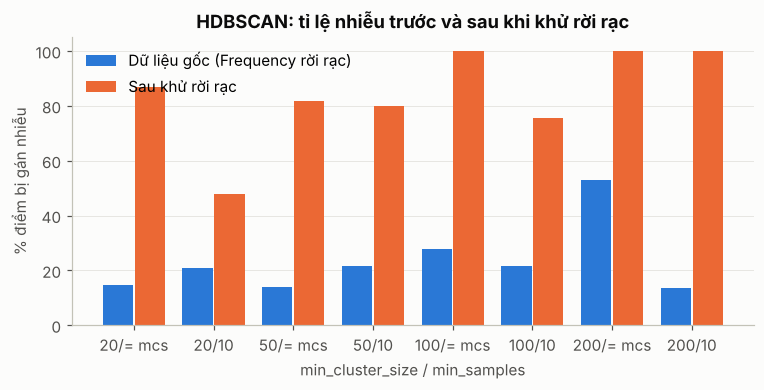

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
idx = [f"{a}/{b}" for a, b in deq.index]
xx = np.arange(len(idx))
orig = [hdb_scan.loc[(a, b), "% nhiễu"] for a, b in deq.index]
ax.bar(xx - .2, orig, width=.38, color=viz.MAIN, label="Dữ liệu gốc (Frequency rời rạc)")
ax.bar(xx + .2, deq["% nhiễu"], width=.38, color=viz.ACCENT, label="Sau khử rời rạc")
ax.set_xticks(xx); ax.set_xticklabels(idx); ax.set_xlabel("min_cluster_size / min_samples")
ax.set_ylabel("% điểm bị gán nhiễu"); ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
ax.set_title("HDBSCAN: tỉ lệ nhiễu trước và sau khi khử rời rạc")
viz.save(fig, "fig29_hdbscan_dequantized"); plt.show()

**Nhận xét – kiểm chứng bằng khử rời rạc:**
- Sau khi cộng một lượng nhiễu nhỏ để "làm mịn" Frequency và Recency (không làm thay đổi thứ tự hay ý nghĩa của dữ liệu), HDBSCAN **gán 48–100% khách là nhiễu**. Với nhiều cấu hình (mcs = 100 hoặc 200, min_samples mặc định), **không còn cụm nào**. Một số cấu hình còn sót lại vài cụm nhỏ (75–87% nhiễu) với ARI so với K-Means thấp và thay đổi thất thường.
- → **Kết luận đã được kiểm chứng:** không gian RFM của bộ dữ liệu này **không có các vùng mật độ cao tách biệt**. Khách hàng phân bố như một **dải liên tục**. Cấu trúc mà DBSCAN/HDBSCAN tìm thấy trên dữ liệu gốc hoàn toàn đến từ tính rời rạc của biến Frequency.
- Kết quả này giải thích vì sao Silhouette của mọi thuật toán đều chỉ ở mức trung bình, và cho thấy với dữ liệu dạng này, **phân khúc là bài toán "chia một dải liên tục thành các vùng có ý nghĩa"**, chứ không phải "phát hiện các nhóm tự nhiên". Các thuật toán chia theo khoảng cách hoặc phân phối (K-Means, GMM) phù hợp hơn các thuật toán dựa trên mật độ cho mục đích này.

### 4.4 Ứng dụng khác của HDBSCAN: điểm bất thường GLOSH
Dù không tìm được phân khúc hữu ích, HDBSCAN vẫn cho ra **điểm bất thường GLOSH** (Global-Local Outlier Score from Hierarchies) cho từng khách. Điểm này dùng để phát hiện những khách hàng có hành vi bất thường so với vùng mật độ xung quanh.

In [9]:
glosh = pd.Series(hdb.outlier_scores_, index=X.index, name="GLOSH")
thr = glosh.quantile(.99)
top = rfm.join(glosh).sort_values("GLOSH", ascending=False)
display(top.head(10)[["Recency", "Frequency", "Monetary", "AOV", "NumProducts", "ReturnRate", "Country", "GLOSH"]])
out = glosh >= thr
cmp_out = pd.DataFrame({"Top 1% GLOSH": rfm[out][["Recency", "Frequency", "Monetary", "AOV", "ReturnRate"]].median(),
                        "Còn lại": rfm[~out][["Recency", "Frequency", "Monetary", "AOV", "ReturnRate"]].median()})
display(cmp_out.T)
print(f"Top 1% GLOSH ({out.sum()} khách) chiếm {100*rfm.loc[out,'Monetary'].sum()/rfm['Monetary'].sum():.1f}% doanh thu; "
      f"{100*(km_lab[out.values]==0).mean():.0f}% thuộc cụm VIP của K-Means")

,Recency,Frequency,Monetary,AOV,NumProducts,ReturnRate,Country,GLOSH
Customer ID,,,,,,,,
16446,0,2,2.900,1.450,3,1.000,United Kingdom,0.980
12748,0,206,"29,819.990",144.757,1766,0.058,United Kingdom,0.975
14911,1,198,"128,768.240",650.345,1785,0.054,EIRE,0.974
17850,372,34,"5,303.480",155.985,21,0.016,United Kingdom,0.970
18102,0,60,"259,657.300","4,327.622",150,0.000,United Kingdom,0.968
16029,38,62,"60,369.930",973.709,43,0.170,United Kingdom,0.967
15098,182,3,"39,619.500","13,206.500",1,0.007,United Kingdom,0.967
14646,1,72,"278,778.020","3,871.917",699,0.001,Netherlands,0.964
16738,297,1,3.750,3.750,1,0.000,United Kingdom,0.962


,Recency,Frequency,Monetary,AOV,ReturnRate
Top 1% GLOSH,5.500,32.500,"33,927.905",970.696,0.012
Còn lại,51.000,2.000,644.270,280.080,0.000


Top 1% GLOSH (44 khách) chiếm 26.1% doanh thu; 70% thuộc cụm VIP của K-Means


**Nhận xét – điểm bất thường GLOSH:**
- 10 khách có điểm GLOSH cao nhất chia làm hai loại:
  - **Khách bán buôn cực lớn**: 14646 (Netherlands, 278.778 £), 18102 (259.657 £), 14911 (EIRE, 198 đơn), 12748 (206 đơn, 1.766 sản phẩm).
  - **Khách có hành vi bất thường thật sự**: 16446 (đơn 80.995 sản phẩm bị hủy, chỉ còn 2,9 £, ReturnRate = 100%); 15098 (3 đơn, chỉ 1 sản phẩm, AOV 13.206 £); 16738 (1 đơn 3,75 £); 17850 (34 đơn nhưng đã 372 ngày không quay lại).
- Top 1% GLOSH (44 khách) chiếm 26,1% doanh thu, và 70% trong số đó thuộc cụm VIP của K-Means. Các khách này có trung vị 32,5 đơn và 33.928 £, so với 2 đơn và 644 £ của phần còn lại.
- → Đây là **giá trị thực tiễn rõ nhất của HDBSCAN** trên bộ dữ liệu này: nó **không phù hợp để phân khúc, nhưng phù hợp để phát hiện bất thường**. Có thể dùng GLOSH để (1) tách các khách bán buôn lớn ra quản lý riêng (key account), và (2) đánh dấu các giao dịch đáng ngờ (đơn khổng lồ bị hủy, đơn chỉ 1 sản phẩm giá trị rất cao) để kiểm tra.

## 5. UMAP + phân cụm
### 5.1 Không gian nhúng UMAP

Thời gian UMAP: 28.4s


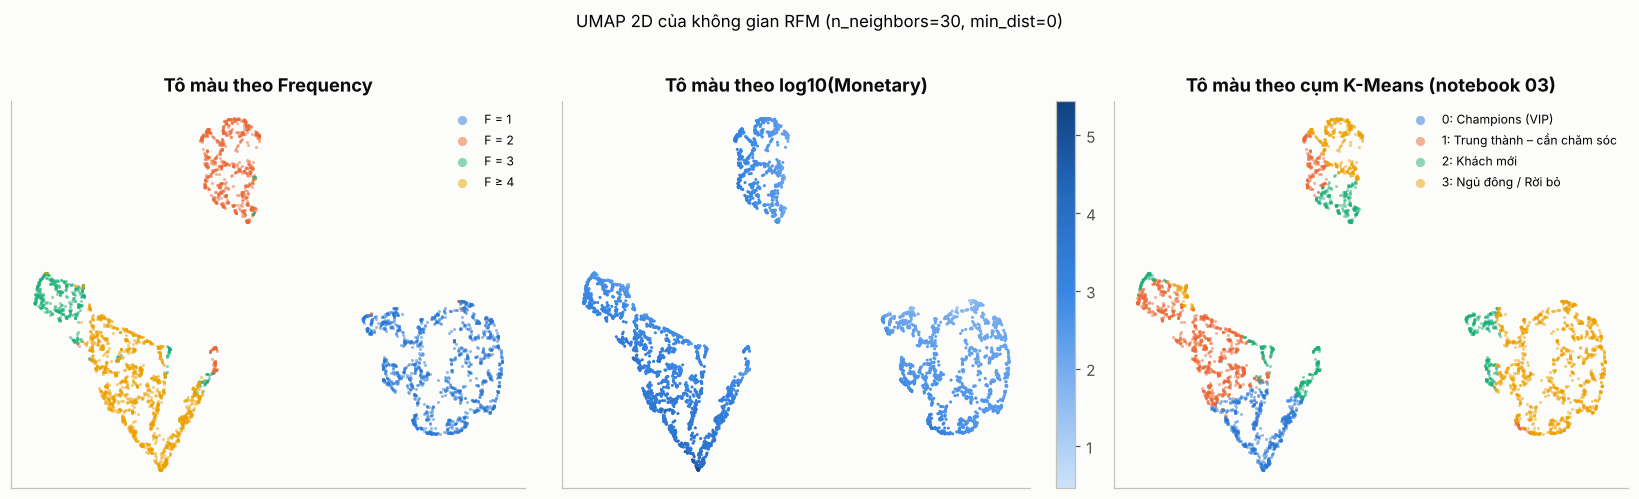

In [10]:
t0 = time.perf_counter()
reducer = umap.UMAP(n_neighbors=30, min_dist=0.0, n_components=2, random_state=SEED)
E = reducer.fit_transform(Xv)
umap_time = time.perf_counter() - t0
print(f"Thời gian UMAP: {umap_time:.1f}s")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
f = rfm["Frequency"].clip(upper=4)
for i, v in enumerate([1, 2, 3, 4]):
    m = f.values == v
    axes[0].scatter(E[m, 0], E[m, 1], s=4, alpha=.5, color=viz.PALETTE[i], linewidths=0, label=f"F = {v}" if v < 4 else "F ≥ 4")
axes[0].set_title("Tô màu theo Frequency"); axes[0].legend(markerscale=3, fontsize=8)
sc = axes[1].scatter(E[:, 0], E[:, 1], s=4, c=np.log10(rfm["Monetary"]), cmap=viz.SEQ_CMAP, linewidths=0)
axes[1].set_title("Tô màu theo log10(Monetary)"); plt.colorbar(sc, ax=axes[1], fraction=.04)
nm = name_clusters(X, km_lab)
for c in range(4):
    m = km_lab == c
    axes[2].scatter(E[m, 0], E[m, 1], s=4, alpha=.5, color=viz.PALETTE[c], linewidths=0, label=f"{c}: {nm[c]}")
axes[2].set_title("Tô màu theo cụm K-Means (notebook 03)"); axes[2].legend(markerscale=3, fontsize=8)
for ax in axes: ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("UMAP 2D của không gian RFM (n_neighbors=30, min_dist=0)", y=1.02, fontsize=11)
fig.tight_layout(); viz.save(fig, "fig30_umap_embedding"); plt.show()

**Nhận xét – không gian nhúng UMAP:**
- UMAP tạo ra **3 "hòn đảo" tách biệt rõ rệt**. Khi tô màu theo Frequency thì thấy ngay: đảo thứ nhất là khách có F = 1, đảo thứ hai là F = 2, và đảo lớn còn lại là F ≥ 3. Một lần nữa, **tính rời rạc của Frequency** quyết định cấu trúc.
- Bên trong mỗi đảo, Monetary và các cụm K-Means thay đổi **liên tục theo dải**, không thành các nhóm riêng biệt. Điều này phù hợp với kết luận của mục 4.3.
- **Lưu ý khi đọc biểu đồ UMAP:** UMAP được thiết kế để làm nổi bật cấu trúc cục bộ, nên khoảng cách giữa các đảo và kích thước mỗi đảo **không phản ánh khoảng cách thật** trong không gian gốc. UMAP rất hữu ích để **trực quan hóa**, nhưng không nên kết luận "có 3 nhóm khách hàng" chỉ từ hình này.

### 5.2 UMAP + HDBSCAN và UMAP + K-Means

In [11]:
rows, umap_labels = [], {}
for mcs in [50, 100, 200]:
    t0 = time.perf_counter(); lab = hdbscan.HDBSCAN(min_cluster_size=mcs).fit_predict(E); t = time.perf_counter() - t0 + umap_time
    umap_labels[f"UMAP + HDBSCAN (mcs={mcs})"] = lab
    rows.append(summarize(f"UMAP + HDBSCAN (mcs={mcs})", lab, t))
for k in [3, 4]:
    t0 = time.perf_counter(); lab = KMeans(k, n_init=10, random_state=SEED).fit_predict(E); t = time.perf_counter() - t0 + umap_time
    umap_labels[f"UMAP + K-Means (K={k})"] = lab
    rows.append(summarize(f"UMAP + K-Means (K={k})", lab, t))
umap_tab = pd.DataFrame(rows).set_index("Phương pháp")
umap_tab["Silhouette (trên không gian UMAP)"] = [internal_metrics(E, l)["Silhouette"] for l in umap_labels.values()]
display(umap_tab)
uh = umap_labels["UMAP + HDBSCAN (mcs=100)"]
pd.crosstab(pd.Series(uh, index=X.index, name="Cụm UMAP+HDBSCAN"), rfm["Frequency"].clip(upper=4).rename("Frequency (≥4 gộp)"))

,Số cụm,% nhiễu,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI với K-Means,Thời gian (s),Silhouette (trên không gian UMAP)
Phương pháp,,,,,,,,
UMAP + HDBSCAN (mcs=50),3,0.000,0.138,1.721,"1,990.488",0.314,28.504,0.702
UMAP + HDBSCAN (mcs=100),3,0.000,0.138,1.721,"1,990.488",0.314,28.508,0.702
UMAP + HDBSCAN (mcs=200),3,0.000,0.138,1.721,"1,990.488",0.314,28.539,0.702
UMAP + K-Means (K=3),3,0.000,0.138,1.721,"1,990.488",0.314,28.468,0.702
UMAP + K-Means (K=4),4,0.000,0.146,1.741,"2,064.788",0.365,28.458,0.645


Frequency (≥4 gộp),1,2,3,4
Cụm UMAP+HDBSCAN,,,,
0,1491,4,0,0
1,0,737,8,1
2,2,88,494,1495


**Nhận xét – UMAP + phân cụm:**
- Trên không gian UMAP, **mọi cấu hình HDBSCAN (mcs = 50, 100, 200) và K-Means với K = 3 cho cùng một kết quả**: 3 cụm trùng với 3 đảo (F = 1 / F = 2 / F ≥ 3), không có điểm nhiễu. Ổn định thì có, nhưng ổn định quanh một cấu trúc giả.
- **Silhouette trên không gian UMAP rất cao (0,70)**, nhưng khi tính lại trên không gian RFM gốc chỉ còn **0,138**, thấp hơn nhiều so với K-Means (0,339). Đây là ví dụ điển hình về **"ảo giác chất lượng"**: đánh giá cụm trong không gian đã được biến đổi phi tuyến (UMAP, t-SNE) sẽ cho kết quả lạc quan sai lệch. Vì vậy nhóm luôn đánh giá trong cùng không gian RFM 3D.
- UMAP + K-Means (K = 4) cũng chỉ đạt Silhouette 0,146. Ngoài ra UMAP tốn khoảng 5 giây (lần chạy đầu khoảng 29 giây do biên dịch numba), chậm hơn K-Means khoảng 200 lần.

## 6. Autoencoder + K-Means trên bộ đặc trưng mở rộng (6 chiều)
Autoencoder phát huy tác dụng khi có nhiều đặc trưng, nên nhóm dùng bộ 6 chiều (R, F, M, Tenure, AOV, NumProducts). Kiến trúc: **6 → 16 → 8 → 3 → 8 → 16 → 6** (tanh, Adam, early stopping), sau đó K-Means với K = 4 trên lớp ẩn 3 chiều.

Số epoch: 335 | R² tái tạo: 0.934 | thời gian: 2.1s | kích thước cụm: [ 793 1415  917 1195]


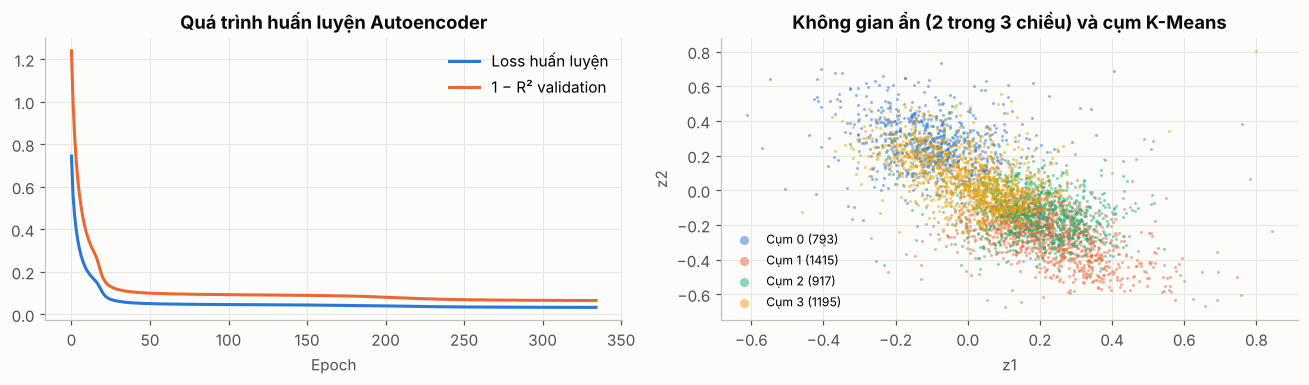

,Silhouette (6D),Davies-Bouldin (6D),Calinski-Harabasz (6D),Silhouette (RFM 3D),Silhouette (latent)
Cấu hình,,,,,
K-Means trực tiếp trên 6D,0.256,1.288,"1,802.528",0.205,NaN
Autoencoder (latent 3D) + K-Means,0.199,1.584,"1,321.302",0.144,0.367


In [12]:
aek = AutoencoderKMeans(n_clusters=4, hidden=(16, 8, 3, 8, 16), random_state=SEED)
t0 = time.perf_counter(); ae_lab = aek.fit_predict(Xe); ae_time = time.perf_counter() - t0
print(f"Số epoch: {aek.ae_.n_iter_} | R² tái tạo: {aek.r2_:.3f} | thời gian: {ae_time:.1f}s | kích thước cụm: {np.bincount(ae_lab)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(aek.ae_.loss_curve_, color=viz.MAIN, label="Loss huấn luyện")
axes[0].plot(1 - np.array(aek.ae_.validation_scores_), color=viz.ACCENT, label="1 − R² validation")
axes[0].set_xlabel("Epoch"); axes[0].set_title("Quá trình huấn luyện Autoencoder"); axes[0].legend()
Z = aek.latent_
for c in range(4):
    m = ae_lab == c
    axes[1].scatter(Z[m, 0], Z[m, 1], s=4, alpha=.5, color=viz.PALETTE[c], linewidths=0, label=f"Cụm {c} ({m.sum()})")
axes[1].set_xlabel("z1"); axes[1].set_ylabel("z2"); axes[1].legend(markerscale=3, fontsize=8)
axes[1].set_title("Không gian ẩn (2 trong 3 chiều) và cụm K-Means")
fig.tight_layout(); viz.save(fig, "fig31_autoencoder"); plt.show()

from sklearn.cluster import KMeans as _KM
km6 = _KM(4, n_init=10, random_state=SEED).fit_predict(Xe)
pd.DataFrame([
    {"Cấu hình": "K-Means trực tiếp trên 6D", **{f"{k} (6D)": v for k, v in internal_metrics(Xe, km6).items()}, "Silhouette (RFM 3D)": internal_metrics(Xv, km6)["Silhouette"]},
    {"Cấu hình": "Autoencoder (latent 3D) + K-Means", **{f"{k} (6D)": v for k, v in internal_metrics(Xe, ae_lab).items()}, "Silhouette (RFM 3D)": internal_metrics(Xv, ae_lab)["Silhouette"],
     "Silhouette (latent)": internal_metrics(Z, ae_lab)["Silhouette"]},
]).set_index("Cấu hình")

**Nhận xét – Autoencoder + K-Means:**
- Autoencoder hội tụ sau 335 epoch (early stopping) với **R² tái tạo = 0,934**: lớp ẩn 3 chiều giữ được khoảng 93% thông tin của 6 đặc trưng, nên việc nén thành công.
- Nhưng **chất lượng phân cụm không tốt hơn**: K-Means trên latent đạt Silhouette 0,199 (đo trên 6D) và 0,144 (đo trên RFM 3D), **thấp hơn K-Means chạy trực tiếp trên 6D** (0,256 và 0,205). Silhouette trên chính không gian latent (0,367) cao hơn, nhưng gặp lại đúng "ảo giác chất lượng" như với UMAP.
- **Nguyên nhân:** autoencoder được huấn luyện để **tái tạo dữ liệu**, không phải để tạo ra các cụm tách biệt. Với chỉ 6 đặc trưng dạng bảng, quan hệ giữa các đặc trưng gần như tuyến tính hoặc đơn điệu, nên không có cấu trúc phi tuyến phức tạp để mạng nơ-ron khai thác. Các phương pháp deep clustering đầy đủ (DEC, IDEC) thêm hàm mất mát phân cụm (KL divergence) để tinh chỉnh biểu diễn; đây là một hướng phát triển. Tuy vậy, chúng thường phát huy tác dụng với dữ liệu nhiều chiều (ảnh, văn bản, chuỗi hành vi), chứ không phải 3–6 đặc trưng RFM.

## 7. Bảng so sánh tổng hợp: phương pháp cổ điển và hiện đại

In [13]:
cfg = {
    "K-Means (K=4)": (lambda: KMeans(4, n_init=10, random_state=SEED), Xv, km_lab, None),
    "DBSCAN (eps=0.3)": (lambda: DBSCAN(eps=0.3, min_samples=MS), Xv, None, None),
    "HDBSCAN (50, 10)": (lambda: hdbscan.HDBSCAN(min_cluster_size=50, min_samples=10), Xv, hdb_lab, hdb_time),
    "UMAP + HDBSCAN (100)": (lambda: UMAPCluster(lambda: hdbscan.HDBSCAN(min_cluster_size=100), random_state=SEED), Xv, None, None),
    "UMAP + K-Means (K=4)": (lambda: UMAPCluster(lambda: KMeans(4, n_init=10, random_state=SEED), random_state=SEED), Xv, None, None),
    "Autoencoder + K-Means (K=4)": (lambda: AutoencoderKMeans(4, random_state=SEED), Xe, ae_lab, ae_time),
}
rows, labels_modern = [], {}
for name, (mk, Xin, lab, t) in cfg.items():
    if lab is None:
        _, lab, t = timed_fit(mk, Xin)
    elif t is None:
        _, _, t = timed_fit(mk, Xin)
    n_runs = 10 if ("UMAP" in name or "Autoencoder" in name) else 20
    st, sd = bootstrap_stability(mk, Xin, np.asarray(lab), n_runs=n_runs, frac=.8, seed=SEED)
    r = summarize(name, lab, t)
    r.update({"Ổn định (ARI TB)": st, "Ổn định (ARI std)": sd, "ARI với baseline RFM": agreement(lab, rule)["ARI"]})
    rows.append(r); labels_modern[name] = np.asarray(lab)

cl = pd.read_csv(OUT / "metrics_classic.csv", index_col=0)
for name in ["Agglomerative (Ward)", "GMM (full)"]:
    c = cl.loc[name]
    rows.append({"Phương pháp": f"{name} (K=4)", "Số cụm": 4, "% nhiễu": 0.0, "Silhouette": c["Silhouette"],
                 "Davies-Bouldin": c["Davies-Bouldin"], "Calinski-Harabasz": c["Calinski-Harabasz"],
                 "ARI với K-Means": agreement(km_lab, classic["Agglomerative" if "Ward" in name else "GMM"])["ARI"],
                 "Thời gian (s)": c["Thời gian (s)"], "Ổn định (ARI TB)": c["Ổn định (ARI TB)"],
                 "Ổn định (ARI std)": c["Ổn định (ARI std)"], "ARI với baseline RFM": c["ARI với baseline RFM"]})
allcmp = pd.DataFrame(rows).set_index("Phương pháp")
order = ["K-Means (K=4)", "Agglomerative (Ward) (K=4)", "GMM (full) (K=4)", "DBSCAN (eps=0.3)", "HDBSCAN (50, 10)",
         "UMAP + HDBSCAN (100)", "UMAP + K-Means (K=4)", "Autoencoder + K-Means (K=4)"]
allcmp = allcmp.reindex(order)
allcmp.insert(0, "Nhóm", ["Cổ điển"] * 3 + ["Hiện đại"] * 5)
allcmp

,Nhóm,Số cụm,% nhiễu,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI với K-Means,Thời gian (s),Ổn định (ARI TB),Ổn định (ARI std),ARI với baseline RFM
Phương pháp,,,,,,,,,,,
K-Means (K=4),Cổ điển,4,0.000,0.339,1.013,"3,300.917",1.000,0.022,0.954,0.042,0.352
Agglomerative (Ward) (K=4),Cổ điển,4,0.000,0.269,1.029,"2,761.370",0.595,0.372,0.436,0.091,0.357
GMM (full) (K=4),Cổ điển,4,0.000,0.337,0.969,"3,099.738",0.687,0.050,0.854,0.149,0.295
DBSCAN (eps=0.3),Hiện đại,4,10.486,0.146,2.211,"1,808.655",0.365,0.030,0.943,0.008,0.251
"HDBSCAN (50, 10)",Hiện đại,5,21.528,0.127,2.304,"1,065.474",0.353,0.067,0.852,0.027,0.216
UMAP + HDBSCAN (100),Hiện đại,3,0.000,0.138,1.721,"1,990.488",0.314,5.477,0.980,0.018,0.279
UMAP + K-Means (K=4),Hiện đại,4,0.000,0.146,1.741,"2,064.788",0.365,5.347,0.894,0.052,0.334
Autoencoder + K-Means (K=4),Hiện đại,4,0.000,0.144,1.597,"1,501.895",0.253,2.064,0.944,0.019,0.316


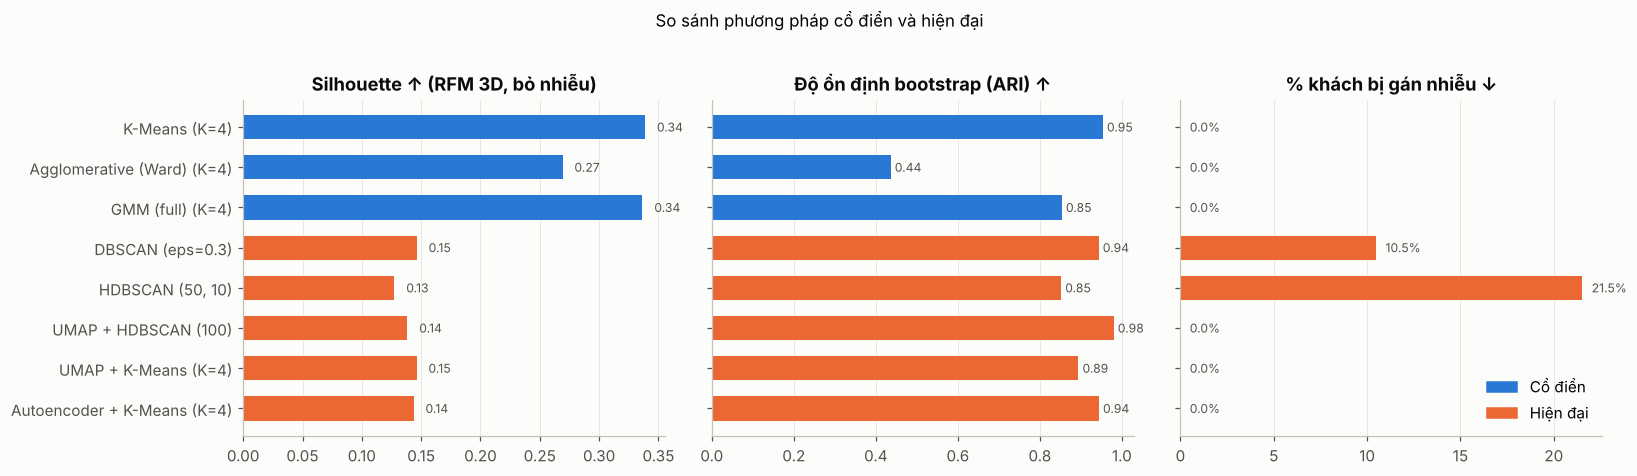

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
names = allcmp.index[::-1]; y = np.arange(len(names))
cols = [viz.MAIN if g == "Cổ điển" else viz.ACCENT for g in allcmp["Nhóm"][::-1]]
for ax, (col, title) in zip(axes, [("Silhouette", "Silhouette ↑ (RFM 3D, bỏ nhiễu)"),
                                   ("Ổn định (ARI TB)", "Độ ổn định bootstrap (ARI) ↑"),
                                   ("% nhiễu", "% khách bị gán nhiễu ↓")]):
    v = allcmp[col][::-1].values
    ax.barh(y, v, color=cols, height=.6)
    for yi, vi in zip(y, v):
        ax.text(vi + (0.01 if col != "% nhiễu" else .5), yi, f"{vi:.2f}" if col != "% nhiễu" else f"{vi:.1f}%", va="center", fontsize=8, color=viz.INK2)
    ax.set_title(title); ax.grid(axis="y", visible=False)
axes[0].set_yticks(y); axes[0].set_yticklabels(names)
from matplotlib.patches import Patch
axes[2].legend(handles=[Patch(color=viz.MAIN, label="Cổ điển"), Patch(color=viz.ACCENT, label="Hiện đại")], loc="lower right")
fig.suptitle("So sánh phương pháp cổ điển và hiện đại", y=1.02, fontsize=11)
fig.tight_layout(); viz.save(fig, "fig32_classic_vs_modern"); plt.show()

**Nhận xét – so sánh tổng hợp 8 phương pháp:**

| Tiêu chí | Kết quả |
|---|---|
| **Silhouette (RFM 3D)** | Ba thuật toán cổ điển (0,27–0,34) **vượt trội** so với mọi phương pháp hiện đại (0,13–0,15) |
| **Davies-Bouldin** | GMM tốt nhất (0,97), K-Means 1,01; các phương pháp hiện đại kém hơn (1,60–2,30) |
| **Độ ổn định** | Phương pháp hiện đại ổn định cao (UMAP+HDBSCAN 0,98; DBSCAN 0,94; AE 0,94), ngang K-Means (0,95). Nguyên nhân là chúng **bám vào các mức Frequency rời rạc**, mà các mức này không đổi khi lấy mẫu con |
| **% nhiễu** | HDBSCAN 21,5% và DBSCAN 10,5%: khoảng 1/5 khách **không được phân khúc**, kể cả nhiều khách giá trị cao |
| **Thời gian** | K-Means 0,02s; UMAP pipeline khoảng 5s (lâu hơn khoảng 200 lần); AE khoảng 2,4s |
| **Diễn giải** | K-Means/GMM: tâm cụm có nghĩa trực tiếp về R, F, M. DBSCAN/HDBSCAN/UMAP: cụm = số đơn hàng. AE: không gian ẩn khó giải thích |

**Phân tích sự khác biệt giữa hai nhóm phương pháp:**
1. **Giả định về cấu trúc dữ liệu.** Phương pháp dựa trên mật độ giả định rằng cụm là các vùng đặc ngăn cách bởi vùng thưa. Dữ liệu RFM ở đây **không có** cấu trúc đó (DBCV ≈ 0; sau khử rời rạc thì 75–100% là nhiễu), nên chúng chỉ "bắt" được tính rời rạc của biến đếm. K-Means và GMM không cần giả định này: chúng **chia không gian** thành các vùng có trung tâm hoặc phân phối riêng, nên vẫn cho kết quả có ý nghĩa trên một dải liên tục.
2. **Học biểu diễn** (UMAP, Autoencoder) mạnh khi dữ liệu nhiều chiều và có cấu trúc phi tuyến. Với 3–6 đặc trưng RFM gần như đơn điệu, chúng **không thêm thông tin**, mà còn làm méo khoảng cách. Phải đánh giá trong không gian gốc mới thấy điều này.
3. **"Mới hơn" không có nghĩa là "tốt hơn" cho mọi bài toán.** Lựa chọn thuật toán phải xuất phát từ **đặc điểm dữ liệu**. Kết luận này phù hợp với thực tế triển khai RFM trong ngành bán lẻ, nơi K-Means vẫn là phương pháp phổ biến nhất.
4. **Giá trị riêng của phương pháp hiện đại** vẫn rõ ràng ở các vai trò khác: HDBSCAN với điểm GLOSH để **phát hiện khách hàng bất thường hoặc key account**; UMAP để **trực quan hóa** và phát hiện vấn đề của dữ liệu (chính UMAP đã làm lộ ra hiệu ứng rời rạc của Frequency).

## 8. Lưu kết quả

In [15]:
lm = pd.DataFrame(labels_modern, index=X.index)
lm["GLOSH"] = glosh.values
lm.to_csv(OUT / "labels_modern.csv")
allcmp.to_csv(OUT / "metrics_all.csv")
db_scan.to_csv(OUT / "scan_dbscan.csv"); hdb_scan.to_csv(OUT / "scan_hdbscan.csv"); deq.to_csv(OUT / "scan_hdbscan_dequantized.csv")
print("Đã lưu: labels_modern.csv, metrics_all.csv, scan_dbscan.csv, scan_hdbscan*.csv")

Đã lưu: labels_modern.csv, metrics_all.csv, scan_dbscan.csv, scan_hdbscan*.csv


## 9. Tổng kết notebook 04

**Kết luận chính của notebook 04:**
1. Các phương pháp hiện đại (DBSCAN, HDBSCAN, UMAP + clustering, Autoencoder + K-Means) **đều cho chất lượng phân khúc kém hơn** các thuật toán cổ điển trên dữ liệu RFM: Silhouette 0,13–0,15 so với 0,27–0,34.
2. **Phát hiện quan trọng nhất:** cấu trúc cụm mà các phương pháp dựa trên mật độ và UMAP tìm thấy **trùng khớp với các giá trị rời rạc của Frequency** (1, 2, 3, 4… đơn). Thí nghiệm khử rời rạc chứng minh rằng ngoài hiệu ứng này, **dữ liệu không có cụm mật độ tự nhiên**: khách hàng tạo thành một dải liên tục.
3. Phát hiện này nhất quán với notebook 03 (GMM suy biến, Silhouette trung bình, dendrogram không có khoảng nhảy rõ). **Lựa chọn cuối cùng: K-Means với K = 4 cho phân khúc**, và có thể **bổ sung HDBSCAN-GLOSH** để đánh dấu khách bất thường hoặc bán buôn lớn.
4. Bài học phương pháp luận cho báo cáo: (a) hiểu giả định của thuật toán trước khi áp dụng; (b) đánh giá trong cùng một không gian và tính đến tỉ lệ nhiễu khi so sánh; (c) thuật toán "mới hơn" không tự động "tốt hơn"; (d) trực quan hóa (UMAP) có thể giúp phát hiện vấn đề của dữ liệu.